# (1) Import libraries

> **Chuyển đổi đầy đủ 3 thực nghiệm A, B, C từ `1. MLP/Func_apxm_MLP.ipynb` sang PyTorch**


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


Using device: cpu


# (2) Data preparation


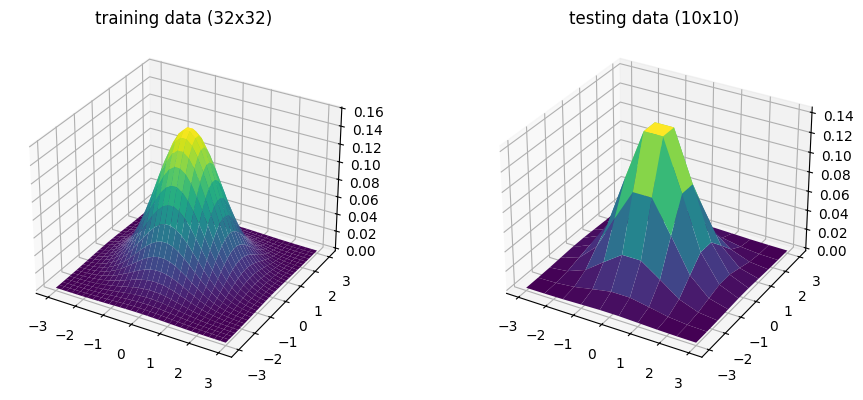

In [2]:
A_grid = 32j
x1, x2 = np.mgrid[-3.0:3.0:A_grid, -3.0:3.0:A_grid]
x1x2 = np.column_stack([x1.flat, x2.flat]).astype(np.float32)
y_tr_grid = multivariate_normal.pdf(x1x2, mean=[0.0, 0.0], cov=np.diag([1.0, 1.0])).astype(np.float32)

x_train = x1x2
y_train = y_tr_grid

A_test = 10j
x1_te, x2_te = np.mgrid[-3.0:3.0:A_test, -3.0:3.0:A_test]
x1x2_te = np.column_stack([x1_te.flat, x2_te.flat]).astype(np.float32)
y_test = multivariate_normal.pdf(x1x2_te, mean=[0.0, 0.0], cov=np.diag([1.0, 1.0])).astype(np.float32)

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(x1, x2, y_train.reshape(x1.shape), cmap='viridis')
ax1.set_title('training data (32x32)')
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(x1_te, x2_te, y_test.reshape(x1_te.shape), cmap='viridis')
ax2.set_title('testing data (10x10)')
plt.tight_layout()
plt.show()


# (3) MLP in PyTorch (`nn.Module`)


In [3]:
class GaussMLP(nn.Module):
    def __init__(self, B=16):
        super().__init__()
        self.fc = nn.Linear(2, B)
        self.act = nn.Sigmoid()
        self.gauss_apxm = nn.Linear(B, 1)
        self.out_act = nn.Sigmoid()

    def forward(self, x):
        x = self.act(self.fc(x))
        return self.out_act(self.gauss_apxm(x))

def train_and_eval_gauss(B, epochs, train_x, train_y, lr=0.01, batch_size=32):
    model = GaussMLP(B=B).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(torch.tensor(train_x), torch.tensor(train_y).unsqueeze(-1)), batch_size=batch_size, shuffle=True)
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        tr_mse = criterion(model(torch.tensor(x_train).to(device)), torch.tensor(y_train).unsqueeze(-1).to(device)).item()
        te_mse = criterion(model(torch.tensor(x1x2_te).to(device)), torch.tensor(y_test).unsqueeze(-1).to(device)).item()
    return model, tr_mse, te_mse

print(GaussMLP(16))


GaussMLP(
  (fc): Linear(in_features=2, out_features=16, bias=True)
  (act): Sigmoid()
  (gauss_apxm): Linear(in_features=16, out_features=1, bias=True)
  (out_act): Sigmoid()
)


# (4) Training and evaluating MLP
### (4.1) Number of training samples (A) (B = 16, C = 120)


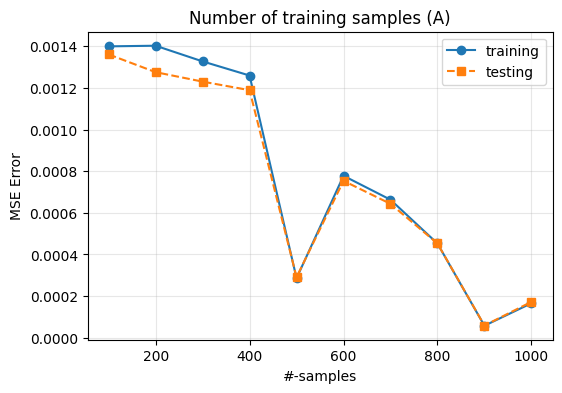

In [4]:
train_error_A, test_error_A, A_array = [], [], []
tot_train = len(x_train)
for A in np.arange(100, tot_train, 100):
    sel = np.random.choice(tot_train, size=A, replace=False)
    _, tr_e, te_e = train_and_eval_gauss(B=16, epochs=120, train_x=x_train[sel], train_y=y_train[sel])
    train_error_A.append(tr_e)
    test_error_A.append(te_e)
    A_array.append(A)

plt.figure(figsize=(6, 4))
plt.plot(A_array, train_error_A, 'o-', label='training')
plt.plot(A_array, test_error_A, 's--', label='testing')
plt.legend(); plt.title('Number of training samples (A)'); plt.xlabel('#-samples'); plt.ylabel('MSE Error')
plt.grid(True, alpha=0.3); plt.show()


### (4.2) Number of hidden nodes (B) (A = 800, C = 120)


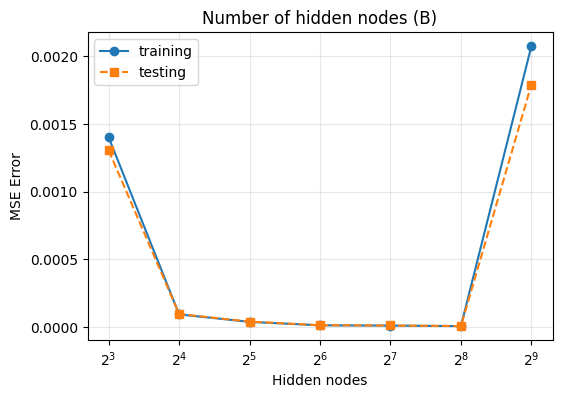

In [5]:
train_error_B, test_error_B, B_array = [], [], []
for B in [8, 16, 32, 64, 128, 256, 512]:
    sel = np.random.choice(tot_train, size=800, replace=False)
    _, tr_e, te_e = train_and_eval_gauss(B=B, epochs=120, train_x=x_train[sel], train_y=y_train[sel])
    train_error_B.append(tr_e)
    test_error_B.append(te_e)
    B_array.append(B)

plt.figure(figsize=(6, 4))
plt.plot(B_array, train_error_B, 'o-', label='training')
plt.plot(B_array, test_error_B, 's--', label='testing')
plt.xscale('log', base=2); plt.legend(); plt.title('Number of hidden nodes (B)'); plt.xlabel('Hidden nodes'); plt.ylabel('MSE Error')
plt.grid(True, alpha=0.3); plt.show()


### (4.3) Number of epochs (C) (A = 800, B = 128) & 3D Surface Verification


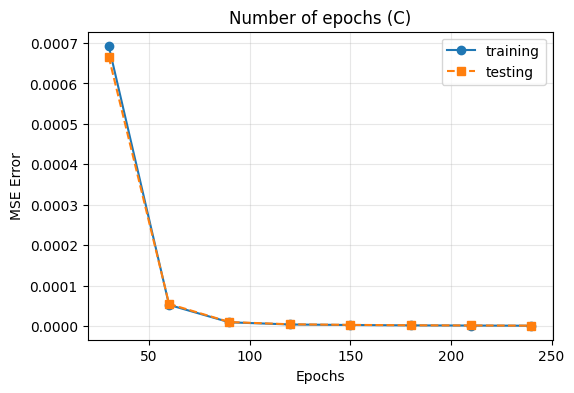

Final GaussMLP(B=128, C=200) -> Test MSE: 1.114317e-06, R2: 99.93%


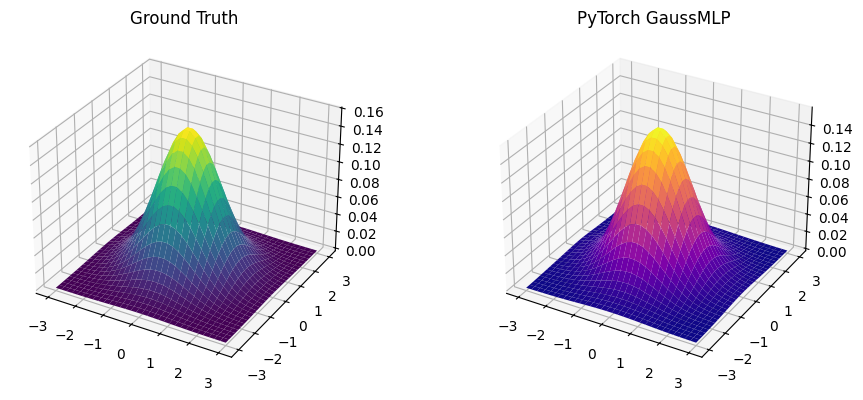

In [6]:
train_error_C, test_error_C, C_array = [], [], []
for C in np.arange(30, 241, 30):
    sel = np.random.choice(tot_train, size=800, replace=False)
    best_model, tr_e, te_e = train_and_eval_gauss(B=128, epochs=int(C), train_x=x_train[sel], train_y=y_train[sel])
    train_error_C.append(tr_e)
    test_error_C.append(te_e)
    C_array.append(C)

plt.figure(figsize=(6, 4))
plt.plot(C_array, train_error_C, 'o-', label='training')
plt.plot(C_array, test_error_C, 's--', label='testing')
plt.legend(); plt.title('Number of epochs (C)'); plt.xlabel('Epochs'); plt.ylabel('MSE Error')
plt.grid(True, alpha=0.3); plt.show()

# 3D comparison
best_model.eval()
with torch.no_grad():
    pred_grid = best_model(torch.tensor(x_train).to(device)).cpu().numpy().reshape(x1.shape)
    r2 = 1.0 - np.sum((y_train.reshape(x1.shape) - pred_grid)**2) / np.sum((y_train.reshape(x1.shape) - y_train.mean())**2)
print(f'Final GaussMLP(B=128, C=200) -> Test MSE: {test_error_C[-1]:.6e}, R2: {r2*100:.2f}%')

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(121, projection='3d'); ax1.plot_surface(x1, x2, y_train.reshape(x1.shape), cmap='viridis'); ax1.set_title('Ground Truth')
ax2 = fig.add_subplot(122, projection='3d'); ax2.plot_surface(x1, x2, pred_grid, cmap='plasma'); ax2.set_title('PyTorch GaussMLP')
plt.tight_layout(); plt.show()
